# 6. Random Forest / Rastgele Orman

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Combine bootstrapped trees, inspect out-of-bag estimates, verify probability averaging and compare two notions of feature importance.

**Türkçe:** Ağaçları birleştirmenin mantığını, OOB ölçümünü ve öznitelik önemlerinin sınırlarını kodla inceliyoruz.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

## Data and evaluation protocol / Veri ve ölçüm düzeni

The target is `B → 0`, `M → 1`. All six tabular classifiers use the **same stratified 80/20 split** (`random_state=42`), so their training CV scores can be compared. The final 114 rows are held out. Hyperparameters are chosen with five-fold CV **inside the 455 training rows**. A scaler belongs in a pipeline so each fold learns its own training minimum and maximum. Trees and GaussianNB do not need scaling.

**Türkçe:** Önce eğitim/test ayrımı yapılır. Ölçekleme ve model seçimi yalnız eğitim verisinden öğrenilir. Test verisi K, C veya derinlik seçmek için kullanılmaz. Eski notlardaki farklı ayrımla üretilmiş örnek yüzdeler bu çalıştırmayla birebir aynı olmak zorunda değildir.

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold

frame = pd.read_csv(CLASSIFICATION_DIR / "datasets" / "data.csv")
X = frame.drop(columns=["id", "diagnosis", "Unnamed: 32"])
y = frame["diagnosis"].map({"B": 0, "M": 1})
assert X.shape == (569, 30) and y.notna().all() and X.notna().all().all()
assert not X.columns.isin(["id", "diagnosis"]).any()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame({"all": y.value_counts(), "train": y_train.value_counts(),
                      "test": y_test.value_counts()}).rename(index={0: "Benign (0)", 1: "Malignant (1)"}))
display(X_train.head(3))
print(f"Train: {X_train.shape}; held-out test: {X_test.shape}")

,all,train,test
diagnosis,,,
Benign (0),357,285,72
Malignant (1),212,170,42


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,...,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,...,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,...,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,...,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151


Train: (455, 30); held-out test: (114, 30)


## Bootstrap and averaging / Bootstrap ve ortalama

Each tree receives a bootstrap sample, and each split considers a random subset of features. About $(1-1/m)^m\approx e^{-1}$ of training rows are absent from one tree's sample. OOB prediction for a row uses only trees that did not train on that row.

For classification, sklearn averages the trees' **class probabilities**:
$$\hat P(c\mid x)=\frac1T\sum_{t=1}^T\hat P_t(c\mid x),\quad
\hat y=\arg\max_c\hat P(c\mid x).$$
This need not equal a strict vote of each tree's hard prediction when leaves contain mixed classes. Randomness reduces tree correlation; averaging mainly reduces variance.

**Türkçe:** OOB, her gözlemi yalnız onu görmemiş ağaçlarla ölçer. Sklearn önce olasılıkları ortalar, sonra en büyük olasılığın sınıfını seçer; karışık yapraklarda bu sonuç katı çoğunluk oylamasından farklı olabilir.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

model = RandomForestClassifier(n_estimators=200, max_features="sqrt", bootstrap=True,
                               oob_score=True, random_state=SEED, n_jobs=1)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1,
                            error_score="raise")
model.fit(X_train, y_train)
display(pd.Series({"training_accuracy": model.score(X_train, y_train),
                   "OOB_accuracy": model.oob_score_, "train_CV_accuracy": cv_scores.mean(),
                   "CV_fold_SD": cv_scores.std()}))
print("Expected absent fraction in one bootstrap:", (1 - 1 / len(X_train)) ** len(X_train))

query = X_test.iloc[:3].to_numpy(dtype=np.float32)
tree_probabilities = np.stack([tree.predict_proba(query) for tree in model.estimators_])
manual_probabilities = tree_probabilities.mean(axis=0)
assert np.allclose(manual_probabilities, model.predict_proba(X_test.iloc[:3]))
display(pd.DataFrame(manual_probabilities, columns=["P(Benign)", "P(Malignant)"]))

training_accuracy    1.000000
OOB_accuracy         0.953846
train_CV_accuracy    0.962637
CV_fold_SD           0.014906
dtype: float64

Expected absent fraction in one bootstrap: 0.36747480743763206


,P(Benign),P(Malignant)
0,0.985,0.015
1,0.000,1.000
2,0.670,0.330


              precision    recall  f1-score   support

      Benign     0.9474    1.0000    0.9730        72
   Malignant     1.0000    0.9048    0.9500        42

    accuracy                         0.9649       114
   macro avg     0.9737    0.9524    0.9615       114
weighted avg     0.9668    0.9649    0.9645       114



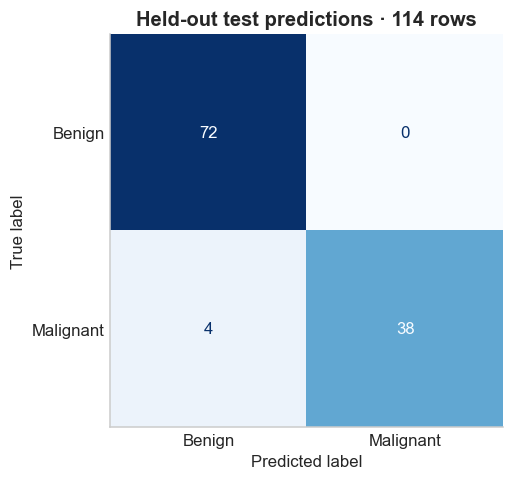

In [4]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

prediction = model.predict(X_test)
test_accuracy = accuracy_score(y_test, prediction)
test_macro_f1 = f1_score(y_test, prediction, average="macro")
print(classification_report(y_test, prediction, target_names=["Benign", "Malignant"], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=["Benign", "Malignant"],
                                       cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Held-out test predictions · 114 rows")
plt.tight_layout()
plt.show()

## Feature importance / Öznitelik önemi

Impurity importance (MDI) sums training impurity reductions. It can favor features with many possible split values. Permutation importance measures how much held-out accuracy falls after shuffling one column. Correlated features can substitute for each other, making either importance hard to interpret causally.

The test set is used here for **final interpretation after fitting**, not to select features or retune the model. Negative permutation importance is possible on a small test set. Error bars are variation across shuffles, not confidence intervals for a population effect.

**Türkçe:** Önem, nedensellik değildir. Bir sütun karıştırıldığında başka ilişkili sütun onun bilgisini taşıyabilir. Bu tabloya bakarak modeli yeniden seçersek yeni bir test kümesi gerekir.

,feature,MDI,test_permutation,shuffle_SD
22,perimeter_worst,0.147912,0.007018,0.007647
23,area_worst,0.132269,0.013158,0.011931
27,concave points_worst,0.110114,0.014035,0.008040
7,concave points_mean,0.088200,0.009649,0.006140
20,radius_worst,0.085116,0.000877,0.007287
0,radius_mean,0.060554,0.000000,0.006795
2,perimeter_mean,0.060465,0.000877,0.007287
3,area_mean,0.044701,0.000877,0.007287
6,concavity_mean,0.044091,0.000000,0.005548
26,concavity_worst,0.032828,0.008772,0.005548


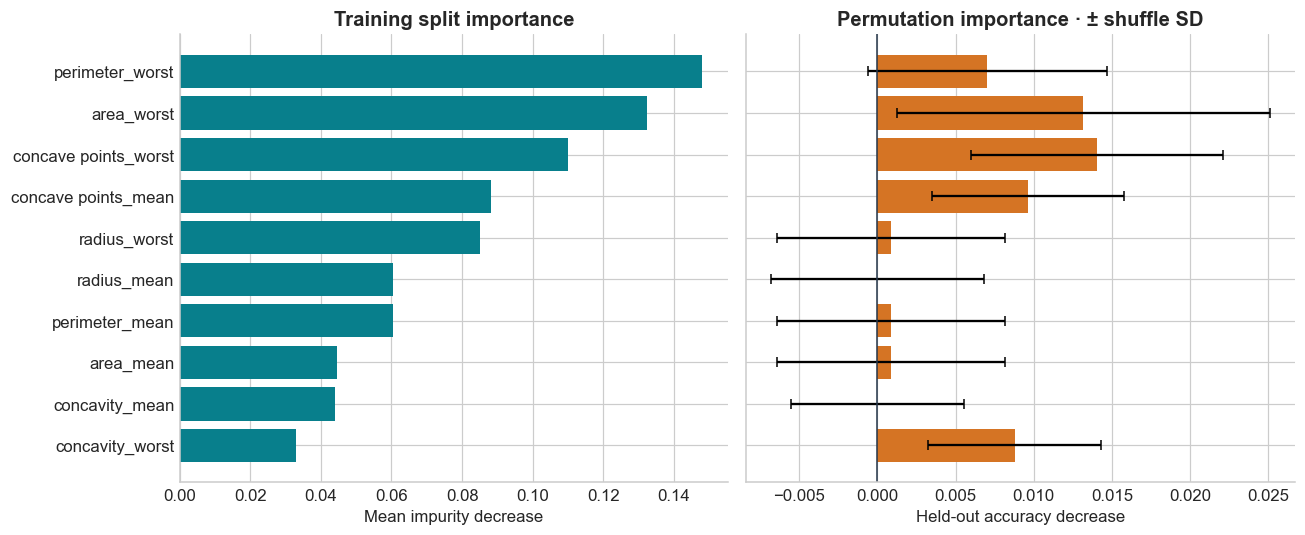

In [5]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(model, X_test, y_test, n_repeats=10,
                                     random_state=SEED, scoring="accuracy", n_jobs=1)
importance = pd.DataFrame({"feature": X.columns, "MDI": model.feature_importances_,
                           "test_permutation": permutation.importances_mean,
                           "shuffle_SD": permutation.importances_std})
display(importance.sort_values("MDI", ascending=False).head(12))
top = importance.nlargest(10, "MDI").sort_values("MDI")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(top.feature, top.MDI, color="#087F8C")
axes[0].set(xlabel="Mean impurity decrease", title="Training split importance")
axes[1].barh(top.feature, top.test_permutation, xerr=top.shuffle_SD, color="#D57424", capsize=3)
axes[1].axvline(0, color="#25364A", linewidth=1)
axes[1].set(xlabel="Held-out accuracy decrease", title="Permutation importance · ± shuffle SD")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [6]:
results = {"chapter": 6, "train_rows": len(X_train), "test_rows": len(X_test),
           "n_estimators": model.n_estimators, "train_cv_accuracy": float(cv_scores.mean()),
           "oob_accuracy": float(model.oob_score_),
           "test_accuracy": float(test_accuracy), "test_macro_f1": float(test_macro_f1),
           "probability_averaging_verified": True}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>